In [61]:
print("Program is developed by",u"\u092A\u094D\u0930\u093F\u092F\u093E\u0902\u0936\u0941\u0020\u092E\u093F\u0936\u094D\u0930\u093E")
print("Program is checked by",u"\u0935\u0948\u0936\u093E\u0932\u0940\u0020\u0907\u0902\u0917\u0933\u0947 / \u0936\u094d\u0935\u0947\u0924\u093e \u0935\u093e\u0928\u0916\u0947\u0921\u093c\u0947")
print("Date of performance - 8 Sep 2026")

Program is developed by प्रियांशु मिश्रा
Program is checked by वैशाली इंगळे / श्वेता वानखेड़े
Date of performance - 8 Sep 2026


In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline

In [90]:
RANDOM_STATE = 91

In [64]:
# 1. Load the Housing Dataset
data = pd.read_csv("housing.csv")

print("Original dataset shape:", data.shape)
display(data.head())

Original dataset shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [65]:
# 2. Data Preprocessing

# Check for existing duplicates and missing values
print("Initial duplicate rows:", data.duplicated().sum())
print("\nInitial missing values:")
print(data.isnull().sum())

# Remove any actual duplicate records
before_duplicates = len(data)
data = data.drop_duplicates()
after_duplicates = len(data)

print(f"\nDuplicate rows removed: {before_duplicates - after_duplicates}")

# Convert missing values to 0
data = data.fillna(0)
print("Missing values converted to 0.")
print("Clean dataset shape:", data.shape)

target_column = "median_house_value"

# FIX: Separate features (X) and target (y) directly from the clean 'data'
X = data.drop(columns=[target_column])
y = data[target_column]

# Keep numerical features for correlation and regression
X = X.select_dtypes(include=np.number)

print("\nFeatures:", end=" ")
print(list(X.columns))
print("\nTarget:", end=" ")
print(target_column)

Initial duplicate rows: 0

Initial missing values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Duplicate rows removed: 0
Missing values converted to 0.
Clean dataset shape: (20640, 10)

Features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']

Target: median_house_value


Features ranked by absolute correlation:


,Absolute_Correlation
median_income,0.688075
latitude,0.144160
total_rooms,0.134153
housing_median_age,0.105623
households,0.065843
total_bedrooms,0.049148
longitude,0.045967
population,0.024650


Selected features: ['median_income', 'latitude']


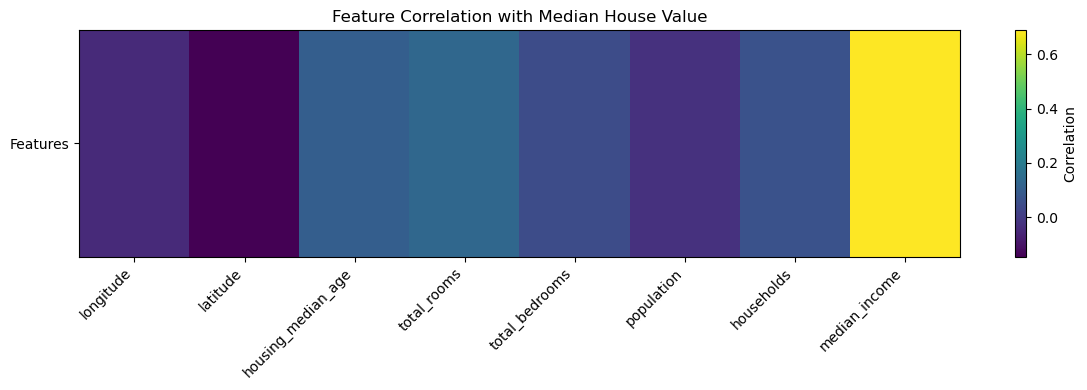

In [66]:
# 3. Find the Selected Features Using Correlation
correlations = (
    pd.concat([X, y], axis=1)
    .corr(numeric_only=True)[target_column]
    .drop(target_column)
)

correlation_table = (
    correlations.abs()
    .sort_values(ascending=False)
    .to_frame("Absolute_Correlation")
)

print("Features ranked by absolute correlation:")
display(correlation_table)

# Select the top two features ONCE
selected_features = correlation_table.index[:2].tolist()
print("Selected features:", selected_features)

# Single-row correlation plot
# FIXED: Increased figure height to 4 and angled labels to prevent tight_layout errors
plt.figure(figsize=(12, 4))
plt.imshow([correlations.values], aspect="auto", cmap="viridis")
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlations)), correlations.index, rotation=45, ha="right")
plt.yticks([0], ["Features"])
plt.title("Feature Correlation with Median House Value")
plt.tight_layout()
plt.show()

In [67]:
# 4. Evaluation Metrics
def calculate_mse(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean((y_true - y_pred) ** 2)

def calculate_mae(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean(np.abs(y_true - y_pred))

def calculate_r2(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

,Training %,Testing %,Train MSE,Test MSE,Train MAE,Test MAE,Train R²,Test R²
0,10,90,6.471738e+09,7.073280e+09,60825.790785,62678.536369,0.493449,0.471152
1,20,80,6.395458e+09,7.171318e+09,60166.573904,62737.622604,0.494603,0.467867
2,30,70,6.893924e+09,7.065079e+09,62158.746353,62602.027501,0.472844,0.473392
3,40,60,6.896709e+09,7.088446e+09,62174.302068,62859.912852,0.472843,0.473757
4,50,50,6.938888e+09,7.084256e+09,62310.781674,62849.020924,0.470962,0.475800
5,60,40,6.952626e+09,7.099576e+09,62345.306524,62902.455129,0.473494,0.473332
6,70,30,7.017327e+09,6.997282e+09,62616.475875,62636.544429,0.472821,0.474898
7,80,20,7.058104e+09,6.825003e+09,62808.267053,61932.069269,0.472469,0.477343
8,90,10,7.034773e+09,6.801338e+09,62717.331801,61712.459516,0.471861,0.487531



Selected Split:
{'Training %': 90, 'Testing %': 10, 'Test MSE': 6801337706.645687, 'Test MAE': 61712.459515523784, 'Test R²': 0.48753101869940774}


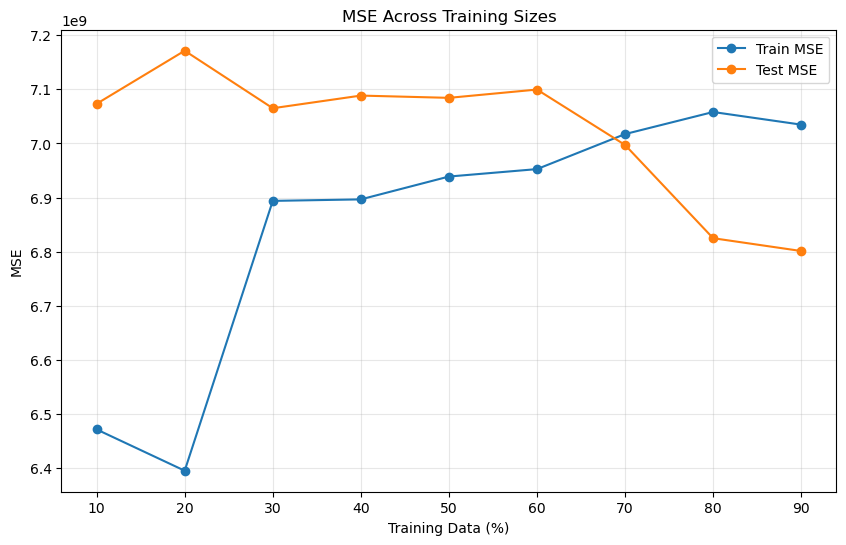

In [92]:
# 5. Effect of Train/Test Split Size
training_percentages = list(range(10, 100, 10))
percentage_results = []
best_result = None

model = LinearRegression()

# Simple Linear Regression uses only the first selected feature
X_linear = data[[selected_features[0]]]

for percentage in training_percentages:
    X_train, X_test, y_train, y_test = train_test_split(
        X_linear, y, train_size=percentage / 100, random_state=RANDOM_STATE
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_mse = calculate_mse(y_train, train_pred)
    test_mse = calculate_mse(y_test, test_pred)
    train_mae = calculate_mae(y_train, train_pred)
    test_mae = calculate_mae(y_test, test_pred)
    train_r2 = calculate_r2(y_train, train_pred)
    test_r2 = calculate_r2(y_test, test_pred)

    percentage_results.append({
        "Training %": percentage,
        "Testing %": 100 - percentage,
        "Train MSE": train_mse,
        "Test MSE": test_mse,
        "Train MAE": train_mae,
        "Test MAE": test_mae,
        "Train R²": train_r2,
        "Test R²": test_r2
    })

    # Select the split using TEST MSE
    if best_result is None or test_mse < best_result["Test MSE"]:
        best_result = {
            "Training %": percentage,
            "Testing %": 100 - percentage,
            "Test MSE": test_mse,
            "Test MAE": test_mae,
            "Test R²": test_r2
        }

percentage_results_df = pd.DataFrame(percentage_results)
display(percentage_results_df)

best_test_size = best_result["Testing %"] / 100
print("\nSelected Split:")
print(best_result)

# Graph comparing Training vs Testing MSE
plt.figure(figsize=(10, 6))
plt.plot(percentage_results_df["Training %"], percentage_results_df["Train MSE"], marker="o", label="Train MSE")
plt.plot(percentage_results_df["Training %"], percentage_results_df["Test MSE"], marker="o", label="Test MSE")
plt.xlabel("Training Data (%)")
plt.ylabel("MSE")
plt.title("MSE Across Training Sizes")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [69]:
# 6. Final Simple Linear Regression
X_selected = X_linear

X_train, X_test, y_train, y_test = train_test_split(
    X_selected, y, test_size=best_test_size, random_state=RANDOM_STATE
)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_train_pred = linear_model.predict(X_train)
linear_pred = linear_model.predict(X_test)

# Evaluation metrics
linear_train_mse = calculate_mse(y_train, linear_train_pred)
linear_train_mae = calculate_mae(y_train, linear_train_pred)
linear_train_r2 = calculate_r2(y_train, linear_train_pred)

linear_mse = calculate_mse(y_test, linear_pred)
linear_mae = calculate_mae(y_test, linear_pred)
linear_r2 = calculate_r2(y_test, linear_pred)

print("Linear Regression Equation:")
print(f"{target_column} = {linear_model.intercept_:.4f} + ({linear_model.coef_[0]:.4f}) * {selected_features[0]}")

print("\nTesting Metrics (Linear)")
print(f"MSE : {linear_mse:.4f}")
print(f"MAE : {linear_mae:.4f}")
print(f"R²  : {linear_r2:.4f}")

Linear Regression Equation:
median_house_value = 45399.6756 + (41722.3304) * median_income

Testing Metrics (Linear)
MSE : 7007890963.8726
MAE : 62714.0540
R²  : 0.4763


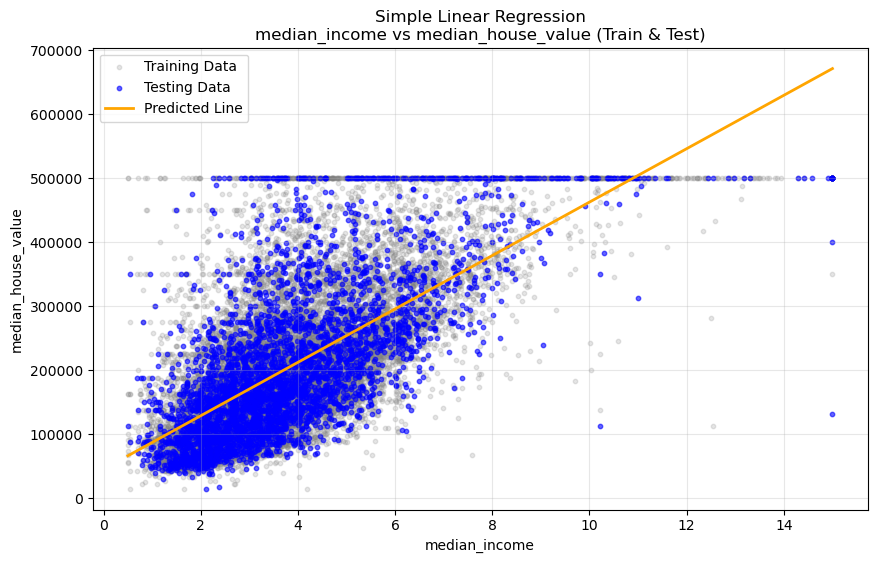

In [70]:
# 7. Actual Values and Regression Line (Optimized with Training Data)
plt.figure(figsize=(10, 6))

# Plot actual TRAINING data points (lighter color to act as a background)
plt.scatter(X_train[selected_features[0]], y_train, s=10, alpha=0.2, color='gray', label="Training Data")

# Plot actual TESTING data points
plt.scatter(X_test[selected_features[0]], y_test, s=10, alpha=0.6, color='blue', label="Testing Data")

# OPTIMIZATION: Get the absolute Min and Max across ALL data to draw the line
x_min = min(X_train[selected_features[0]].min(), X_test[selected_features[0]].min())
x_max = max(X_train[selected_features[0]].max(), X_test[selected_features[0]].max())

# Create a tiny DataFrame with just those 2 points
x_line_df = pd.DataFrame({selected_features[0]: [x_min, x_max]})

# Predict only 2 values for the line endpoints
y_line = linear_model.predict(x_line_df)

# Draw the regression line
plt.plot([x_min, x_max], y_line, color="orange", linewidth=2, label="Predicted Line")

plt.xlabel(selected_features[0])
plt.ylabel(target_column)
plt.title(f"Simple Linear Regression\n{selected_features[0]} vs {target_column} (Train & Test)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [71]:
# 9. Polynomial Regression (Degree 2)
# Using both selected features as mapped out by correlation
X_poly = data[selected_features]

X_poly_train, X_poly_test, y_poly_train, y_poly_test = train_test_split(
    X_poly, y, test_size=best_test_size, random_state=RANDOM_STATE
)

# Pipeline specifically structured to assignment template requirements
polynomial_model = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("linear", LinearRegression())
])

polynomial_model.fit(X_poly_train, y_poly_train)

poly_train_pred = polynomial_model.predict(X_poly_train)
poly_pred = polynomial_model.predict(X_poly_test)

poly_mse = calculate_mse(y_poly_test, poly_pred)
poly_mae = calculate_mae(y_poly_test, poly_pred)
poly_r2 = calculate_r2(y_poly_test, poly_pred)

print("Polynomial Regression (Degree 2)")
print("\nTesting Metrics (Polynomial)")
print(f"MSE : {poly_mse:.4f}")
print(f"MAE : {poly_mae:.4f}")
print(f"R²  : {poly_r2:.4f}")

Polynomial Regression (Degree 2)

Testing Metrics (Polynomial)
MSE : 6747671860.1949
MAE : 61355.2921
R²  : 0.4957


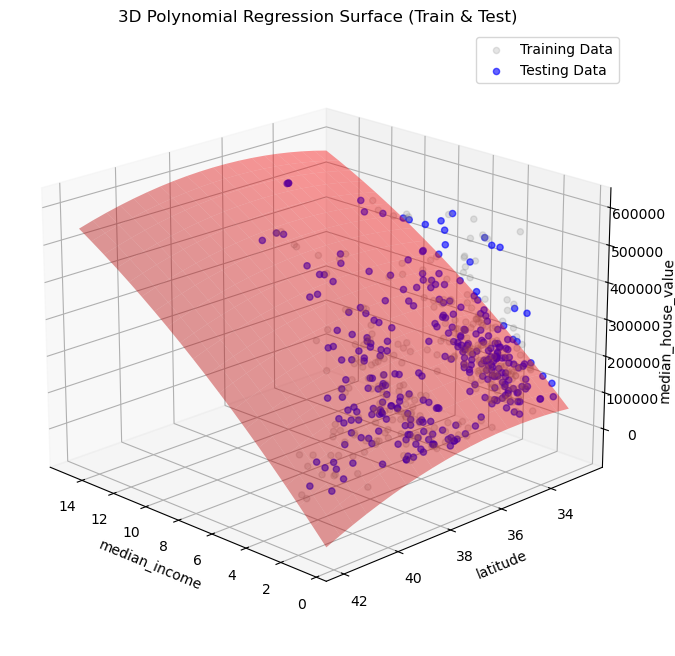

In [72]:
# 9. 3D Regression Plane (with Training and Testing Data)
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Limit points to prevent performance issues and visual clutter
limit = 300 

# Plot actual TRAINING data points (gray background)
# FIXED: Using correct variable 'X_poly_train' and extracting .values to prevent index errors
ax.scatter(X_poly_train[selected_features[0]].values[:limit], 
           X_poly_train[selected_features[1]].values[:limit], 
           y_poly_train.values[:limit], color='gray', label='Training Data', alpha=0.2)

# Plot actual TESTING data points (blue front)
# FIXED: Using correct variable 'X_poly_test'
ax.scatter(X_poly_test[selected_features[0]].values[:limit], 
           X_poly_test[selected_features[1]].values[:limit], 
           y_poly_test.values[:limit], color='blue', label='Testing Data', alpha=0.6)

# OPTIMIZATION: Get the absolute Min and Max across ALL data for the 3D grid
x_min = min(X_poly_train[selected_features[0]].min(), X_poly_test[selected_features[0]].min())
x_max = max(X_poly_train[selected_features[0]].max(), X_poly_test[selected_features[0]].max())
y_min = min(X_poly_train[selected_features[1]].min(), X_poly_test[selected_features[1]].min())
y_max = max(X_poly_train[selected_features[1]].max(), X_poly_test[selected_features[1]].max())

# Create the meshgrid using the absolute boundaries
x_grid = np.linspace(x_min, x_max, 20)
y_grid = np.linspace(y_min, y_max, 20)
xx, yy = np.meshgrid(x_grid, y_grid)

surf_df = pd.DataFrame({
    selected_features[0]: xx.ravel(), 
    selected_features[1]: yy.ravel()
})

# Predict surface values
# FIXED: Changed from 'poly_pipe' to your actual pipeline name 'polynomial_model'
zz = polynomial_model.predict(surf_df).reshape(xx.shape)

# Plot the regression surface
ax.plot_surface(xx, yy, zz, color='red', alpha=0.4)

# Formatting
ax.set_xlabel(selected_features[0])
ax.set_ylabel(selected_features[1])
ax.set_zlabel(target_column)
ax.set_title('3D Polynomial Regression Surface (Train & Test)')
ax.legend()

# Adjust viewing angle
ax.view_init(elev=20, azim=135)
plt.show()

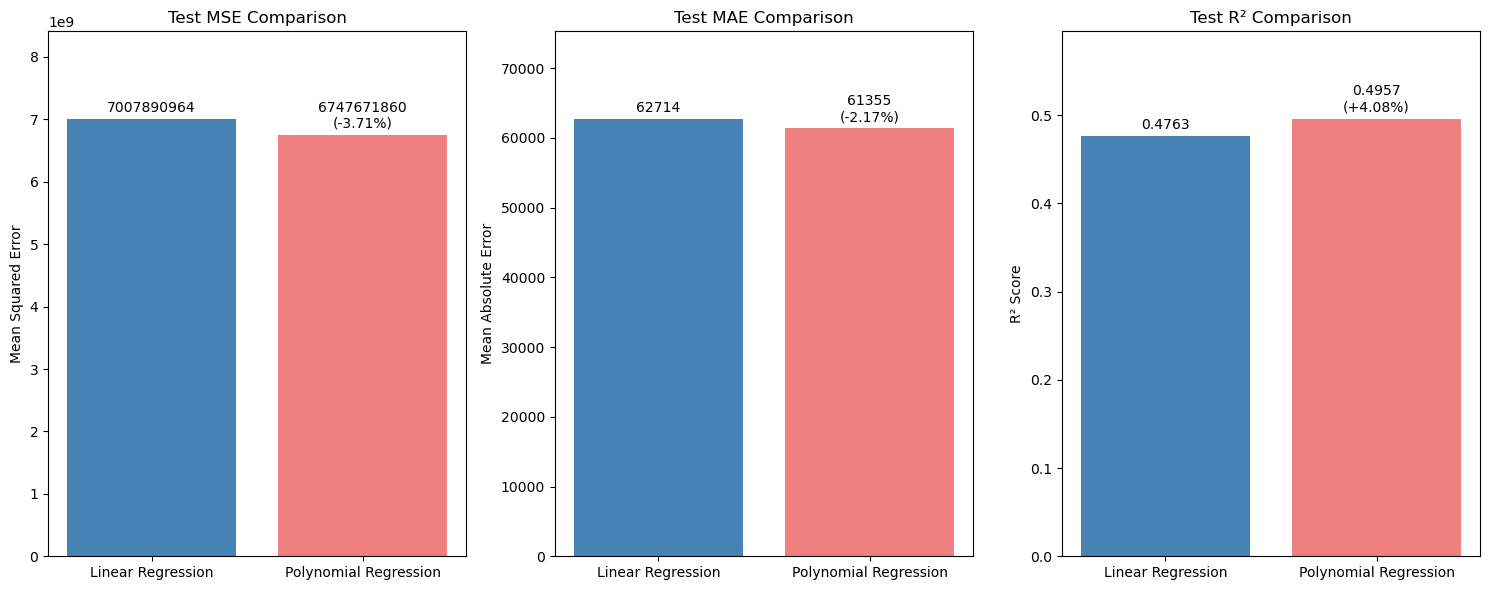

In [73]:
# 10. Compare Models using Bar Graphs (Percentage directly above bars)
models = ['Linear Regression', 'Polynomial Regression']
mse_scores = [linear_mse, poly_mse]
mae_scores = [linear_mae, poly_mae]
r2_scores = [linear_r2, poly_r2]

# Calculate percentage changes (Polynomial relative to Linear)
mse_pct = ((poly_mse - linear_mse) / linear_mse) * 100
mae_pct = ((poly_mae - linear_mae) / linear_mae) * 100
r2_pct = ((poly_r2 - linear_r2) / linear_r2) * 100

# Increased height slightly to fit double-line labels
fig, axes = plt.subplots(1, 3, figsize=(15, 6)) 

# Plot MSE
bars1 = axes[0].bar(models, mse_scores, color=['steelblue', 'lightcoral'])
axes[0].set_title('Test MSE Comparison')
axes[0].set_ylabel('Mean Squared Error')
# Custom labels: Raw value for Linear, Raw value + Percentage for Polynomial
axes[0].bar_label(bars1, labels=[f'{linear_mse:.0f}', f'{poly_mse:.0f}\n({mse_pct:+.2f}%)'], padding=3)

# Plot MAE
bars2 = axes[1].bar(models, mae_scores, color=['steelblue', 'lightcoral'])
axes[1].set_title('Test MAE Comparison')
axes[1].set_ylabel('Mean Absolute Error')
axes[1].bar_label(bars2, labels=[f'{linear_mae:.0f}', f'{poly_mae:.0f}\n({mae_pct:+.2f}%)'], padding=3)

# Plot R2
bars3 = axes[2].bar(models, r2_scores, color=['steelblue', 'lightcoral'])
axes[2].set_title('Test R² Comparison')
axes[2].set_ylabel('R² Score')
axes[2].bar_label(bars3, labels=[f'{linear_r2:.4f}', f'{poly_r2:.4f}\n({r2_pct:+.2f}%)'], padding=3)

# Increased margin at the top of the bars to fit the 2-line labels without clipping
for ax in axes:
    ax.margins(y=0.2)

plt.tight_layout()
plt.show()

In [74]:
# Take live value from user and predict
feature_name = selected_features[0]

try:
    user_input = float(input(f"Enter a live value for {feature_name} to predict the target: "))
    
    # Package input into a DataFrame to match training format
    input_df = pd.DataFrame([[user_input]], columns=[feature_name])
    
    # Predict using your existing linear_model
    live_prediction = linear_model.predict(input_df)
    
    print(f"\nPredicted House Value for {feature_name} = {user_input} is: {live_prediction[0]:.4f}")
except ValueError:
    print("Invalid input. Please enter a valid number.")

Enter a live value for median_income to predict the target:  8.9



Predicted House Value for median_income = 8.9 is: 416728.4166
